# Autoencoder Baseline Model

- **baseline**: 10 features (CAN_ID, DLC, Byte0 to Byte7)
- **time**: 12 features (the same 10 plus `time_diff` and `can_id_time_diff`)

In [ ]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

## 1. Load Data
- train_scaled / validation_scaled (10 features)
- train_scaled_time / validation_scaled_time (12 features)

In [ ]:
with zipfile.ZipFile("CAN_Bus_Preprocessed_Data.zip") as z:
    z.extract("train_scaled.parquet", "data")
    z.extract("validation_scaled.parquet", "data")

with zipfile.ZipFile("CAN_Bus_Preprocessed_Data_Time_Features.zip") as z:
    z.extract("train_scaled_time.parquet", "data")
    z.extract("validation_scaled_time.parquet", "data")

train_df = {
    "baseline": pd.read_parquet("data/train_scaled.parquet"),
    "time": pd.read_parquet("data/train_scaled_time.parquet"),
}
val_df = {
    "baseline": pd.read_parquet("data/validation_scaled.parquet"),
    "time": pd.read_parquet("data/validation_scaled_time.parquet"),
}

x_train = {name: df.values.astype("float32") for name, df in train_df.items()}
x_val = {name: df.values.astype("float32") for name, df in val_df.items()}

for name in x_train:
    print(name, "train:", x_train[name].shape, "validation:", x_val[name].shape)

baseline train: (791096, 10) validation: (197775, 10)
time train: (791096, 12) validation: (197775, 12)


In [ ]:
same_train = np.allclose(x_train["baseline"], x_train["time"][:, :10])
same_val = np.allclose(x_val["baseline"], x_val["time"][:, :10])
print("Same rows in train:", same_train)
print("Same rows in validation:", same_val)

Same rows in train: True
Same rows in validation: True


## 2. Build the model
- Encoder: n -> 8 -> 4 (bottleneck)
- Decoder: 4 -> 8 -> n
- ReLU in the hidden layers, sigmoid at the output because the data is scaled between 0 and 1
- Loss: MSE, optimizer: Adam

The input size is taken from the data, so the same function works for 10 and 12 features.

In [ ]:
def build_model(n_features):
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(8, activation="relu"),
        layers.Dense(4, activation="relu"),
        layers.Dense(8, activation="relu"),
        layers.Dense(n_features, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="mse")
    return model


build_model(x_train["time"].shape[1]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │           108 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 288 (1.12 KB)

 Trainable params: 288 (1.12 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Training
Same settings for both: 20 epochs, batch size 256, seed 42 reset before each model.

In [ ]:
models = {}
histories = {}

for name in x_train:
    print(f"\nTraining the {name} model")
    tf.keras.utils.set_random_seed(42)
    model = build_model(x_train[name].shape[1])

    history = model.fit(
        x_train[name], x_train[name],
        validation_data=(x_val[name], x_val[name]),
        epochs=20,
        batch_size=256,
        verbose=2
    )

    models[name] = model
    histories[name] = history.history


Training the baseline model


Epoch 1/20


3091/3091 - 5s - 2ms/step - loss: 0.0390 - val_loss: 0.0183


Epoch 2/20


3091/3091 - 5s - 2ms/step - loss: 0.0175 - val_loss: 0.0147


Epoch 3/20


... (71 outputs left out)

Epoch 19/20


3091/3091 - 4s - 1ms/step - loss: 0.0112 - val_loss: 0.0115


Epoch 20/20


3091/3091 - 4s - 1ms/step - loss: 0.0111 - val_loss: 0.0114


## 4. Draw Training / Validation Loss

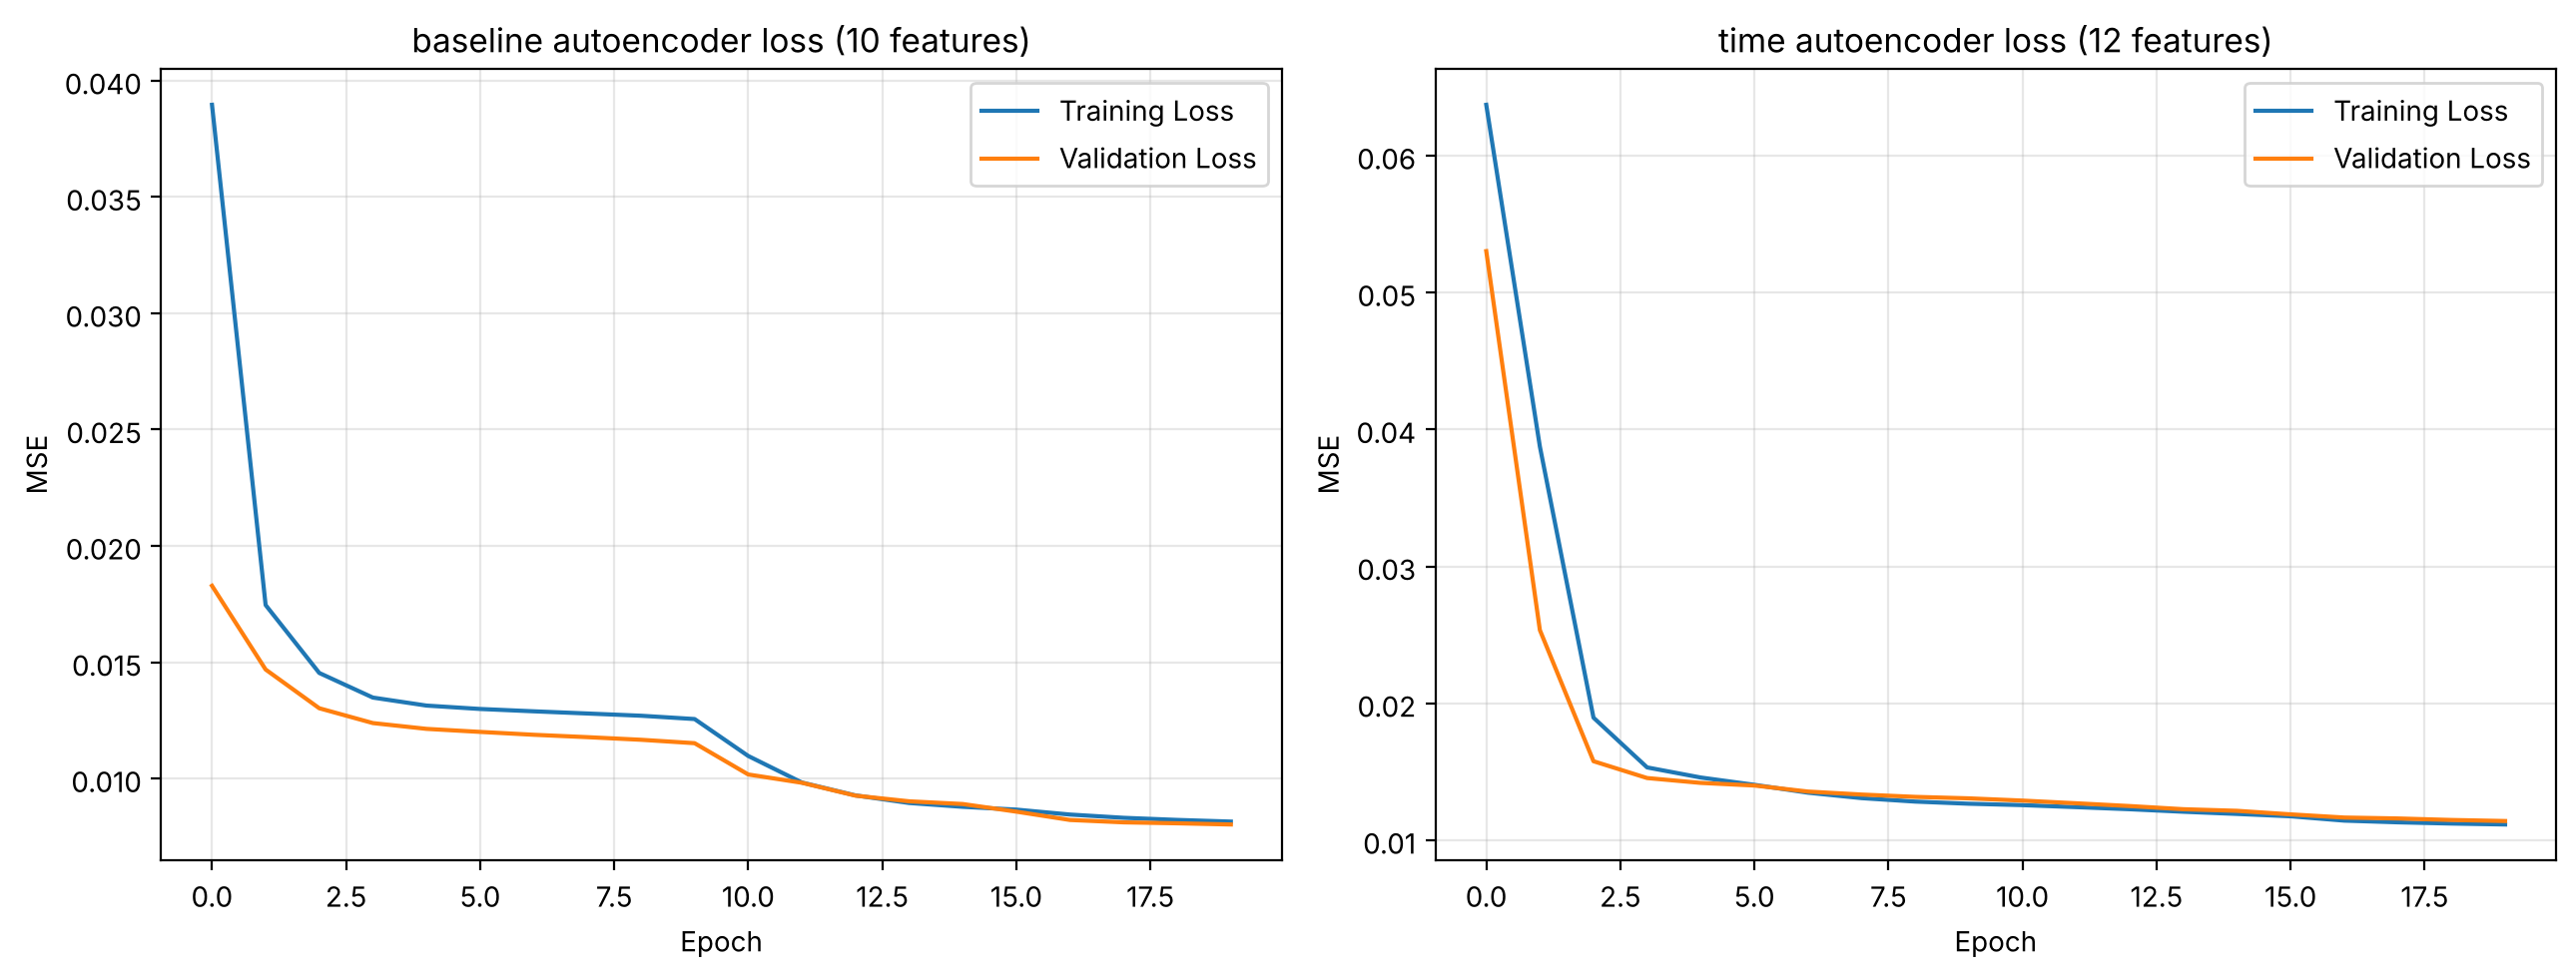

baseline: last train loss 0.008152, last validation loss 0.008027
time: last train loss 0.011149, last validation loss 0.011402


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, histories):
    ax.plot(histories[name]["loss"], label="Training Loss")
    ax.plot(histories[name]["val_loss"], label="Validation Loss")
    ax.set_title(f"{name} autoencoder loss ({x_train[name].shape[1]} features)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

for name, h in histories.items():
    print(f"{name}: last train loss {h['loss'][-1]:.6f}, last validation loss {h['val_loss'][-1]:.6f}")

## 5. Calculate Reconstruction Error

In [ ]:
train_errors = {}
val_errors = {}
feature_errors = {}

for name, model in models.items():
    train_pred = model.predict(x_train[name], batch_size=4096, verbose=0)
    val_pred = model.predict(x_val[name], batch_size=4096, verbose=0)

    train_errors[name] = np.mean((x_train[name] - train_pred) ** 2, axis=1)
    val_errors[name] = np.mean((x_val[name] - val_pred) ** 2, axis=1)

    # error of every feature on the validation set
    feature_errors[name] = np.mean((x_val[name] - val_pred) ** 2, axis=0)

    print(f"\n{name}")
    print("Train error mean:", round(train_errors[name].mean(), 6))
    print("Validation error mean:", round(val_errors[name].mean(), 6))
    print("Validation error max:", round(val_errors[name].max(), 6))


baseline
Train error mean: 0.008136
Validation error mean: 0.008027
Validation error max: 0.140589



time
Train error mean: 0.011122
Validation error mean: 0.011402
Validation error max: 0.123525


### Error distribution (train vs validation)
If the two distributions look the same, the model rebuilds normal messages it did not see as well as the ones it trained on.

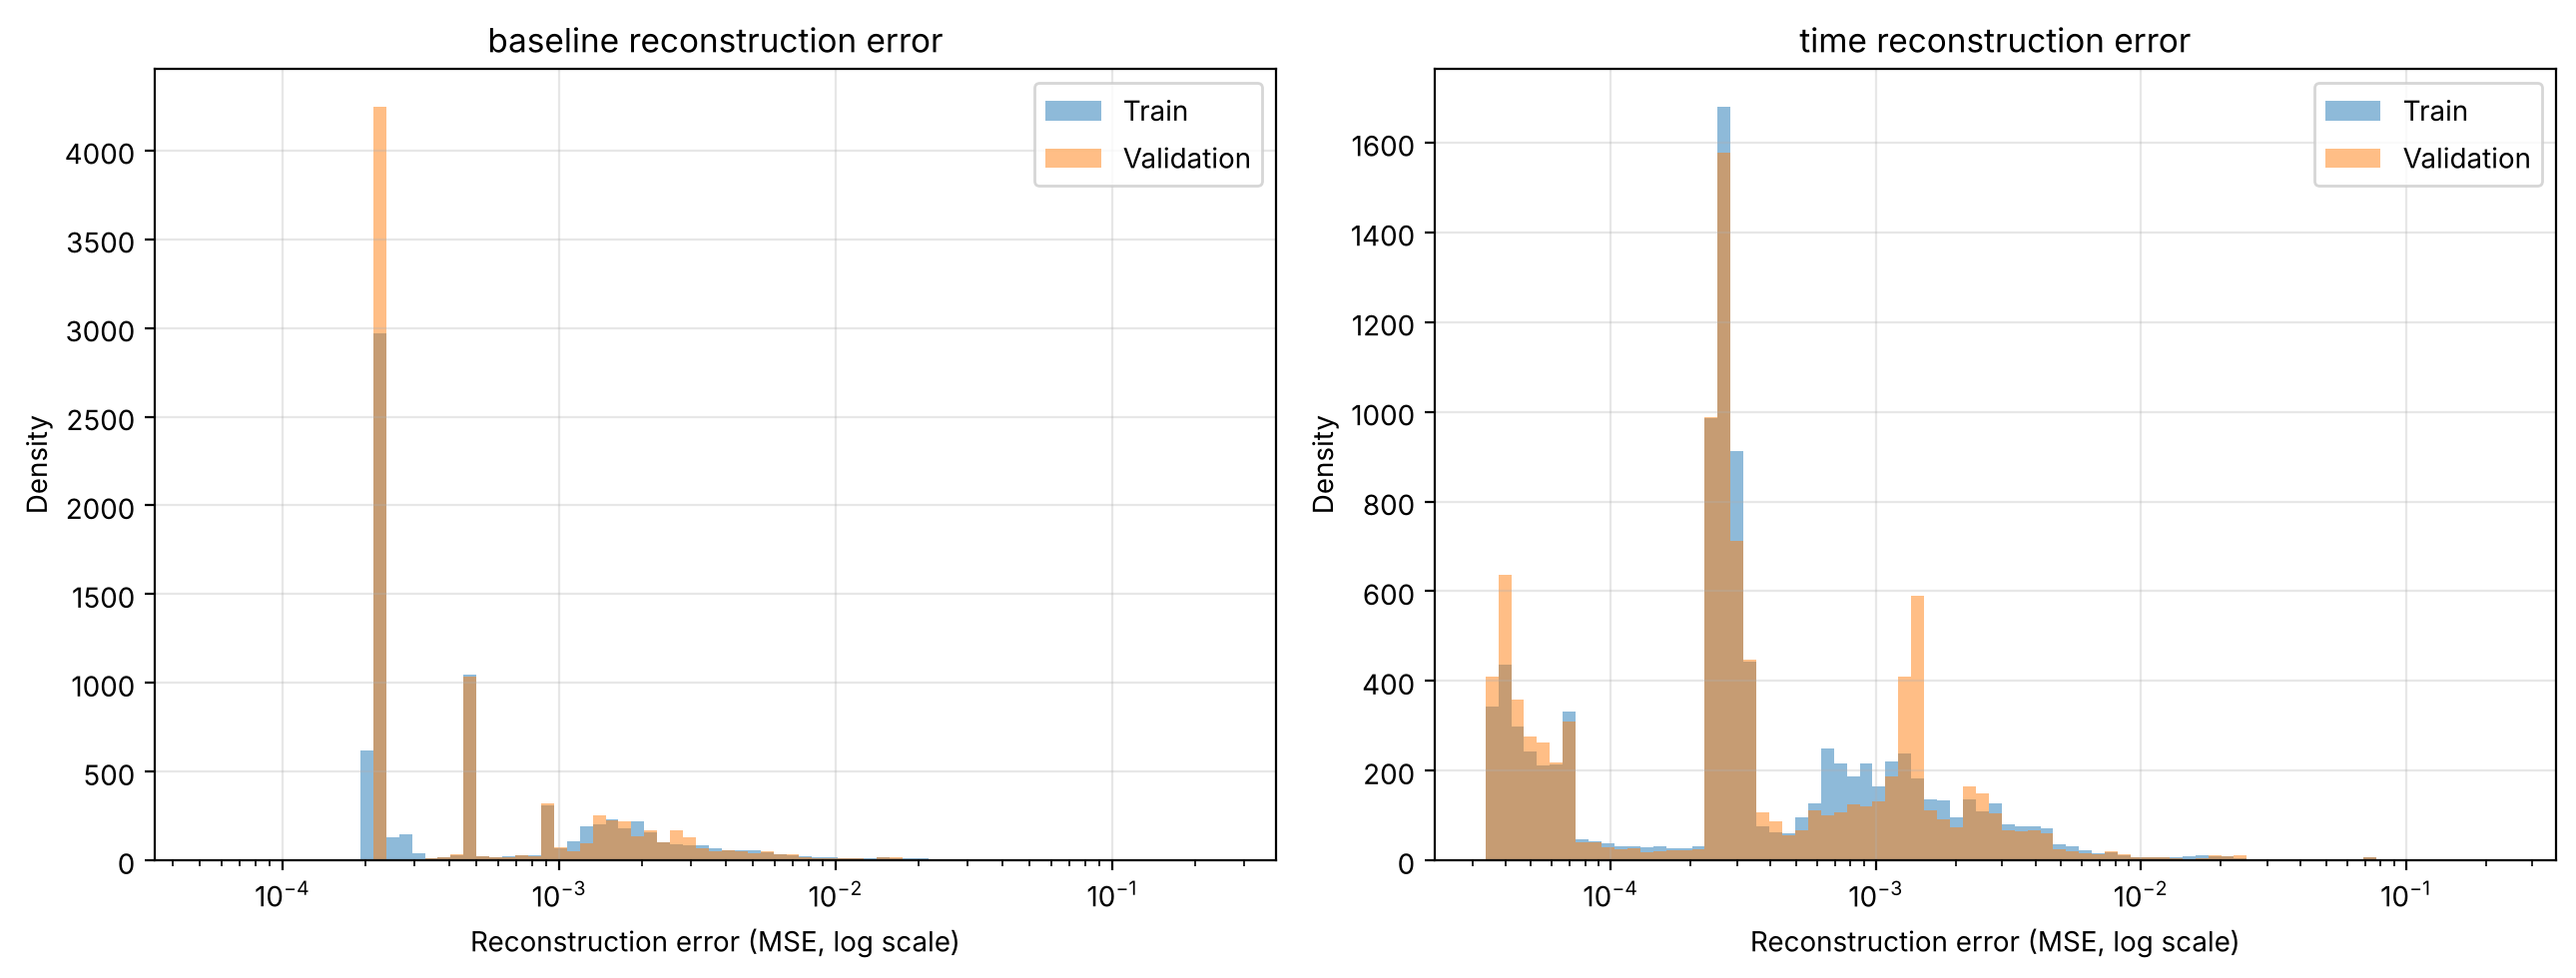

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, models):
    all_errors = np.concatenate([train_errors[name], val_errors[name]])
    low = all_errors[all_errors > 0].min()
    bins = np.logspace(np.log10(low), np.log10(all_errors.max()), 80)
    ax.hist(train_errors[name], bins=bins, alpha=0.5, density=True, label="Train")
    ax.hist(val_errors[name], bins=bins, alpha=0.5, density=True, label="Validation")
    ax.set_xscale("log")
    ax.set_title(f"{name} reconstruction error")
    ax.set_xlabel("Reconstruction error (MSE, log scale)")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Error per feature
The total MSE of the two models can not be compared directly (10 columns vs 12 columns),
so we compare them on the 10 features they share.

In [ ]:
per_feature = pd.DataFrame({
    "baseline": pd.Series(feature_errors["baseline"], index=train_df["baseline"].columns),
    "time": pd.Series(feature_errors["time"], index=train_df["time"].columns),
}).reindex(train_df["time"].columns)
print(per_feature.round(6))

shared = train_df["baseline"].columns
print("\nValidation error on the 10 shared features")
print("baseline:", round(per_feature.loc[shared, "baseline"].mean(), 6))
print("time:", round(per_feature.loc[shared, "time"].mean(), 6))

                  baseline      time
CAN_ID            0.007692  0.007982
DLC               0.006074  0.013944
Byte0             0.007310  0.004138
Byte1             0.011354  0.010799
Byte2             0.011999  0.007542
Byte3             0.011472  0.006460
Byte4             0.009258  0.018252
Byte5             0.005953  0.005153
Byte6             0.002267  0.045901
Byte7             0.006888  0.010781
time_diff              NaN  0.005648
can_id_time_diff       NaN  0.000201

Validation error on the 10 shared features
baseline: 0.008027
time: 0.013095


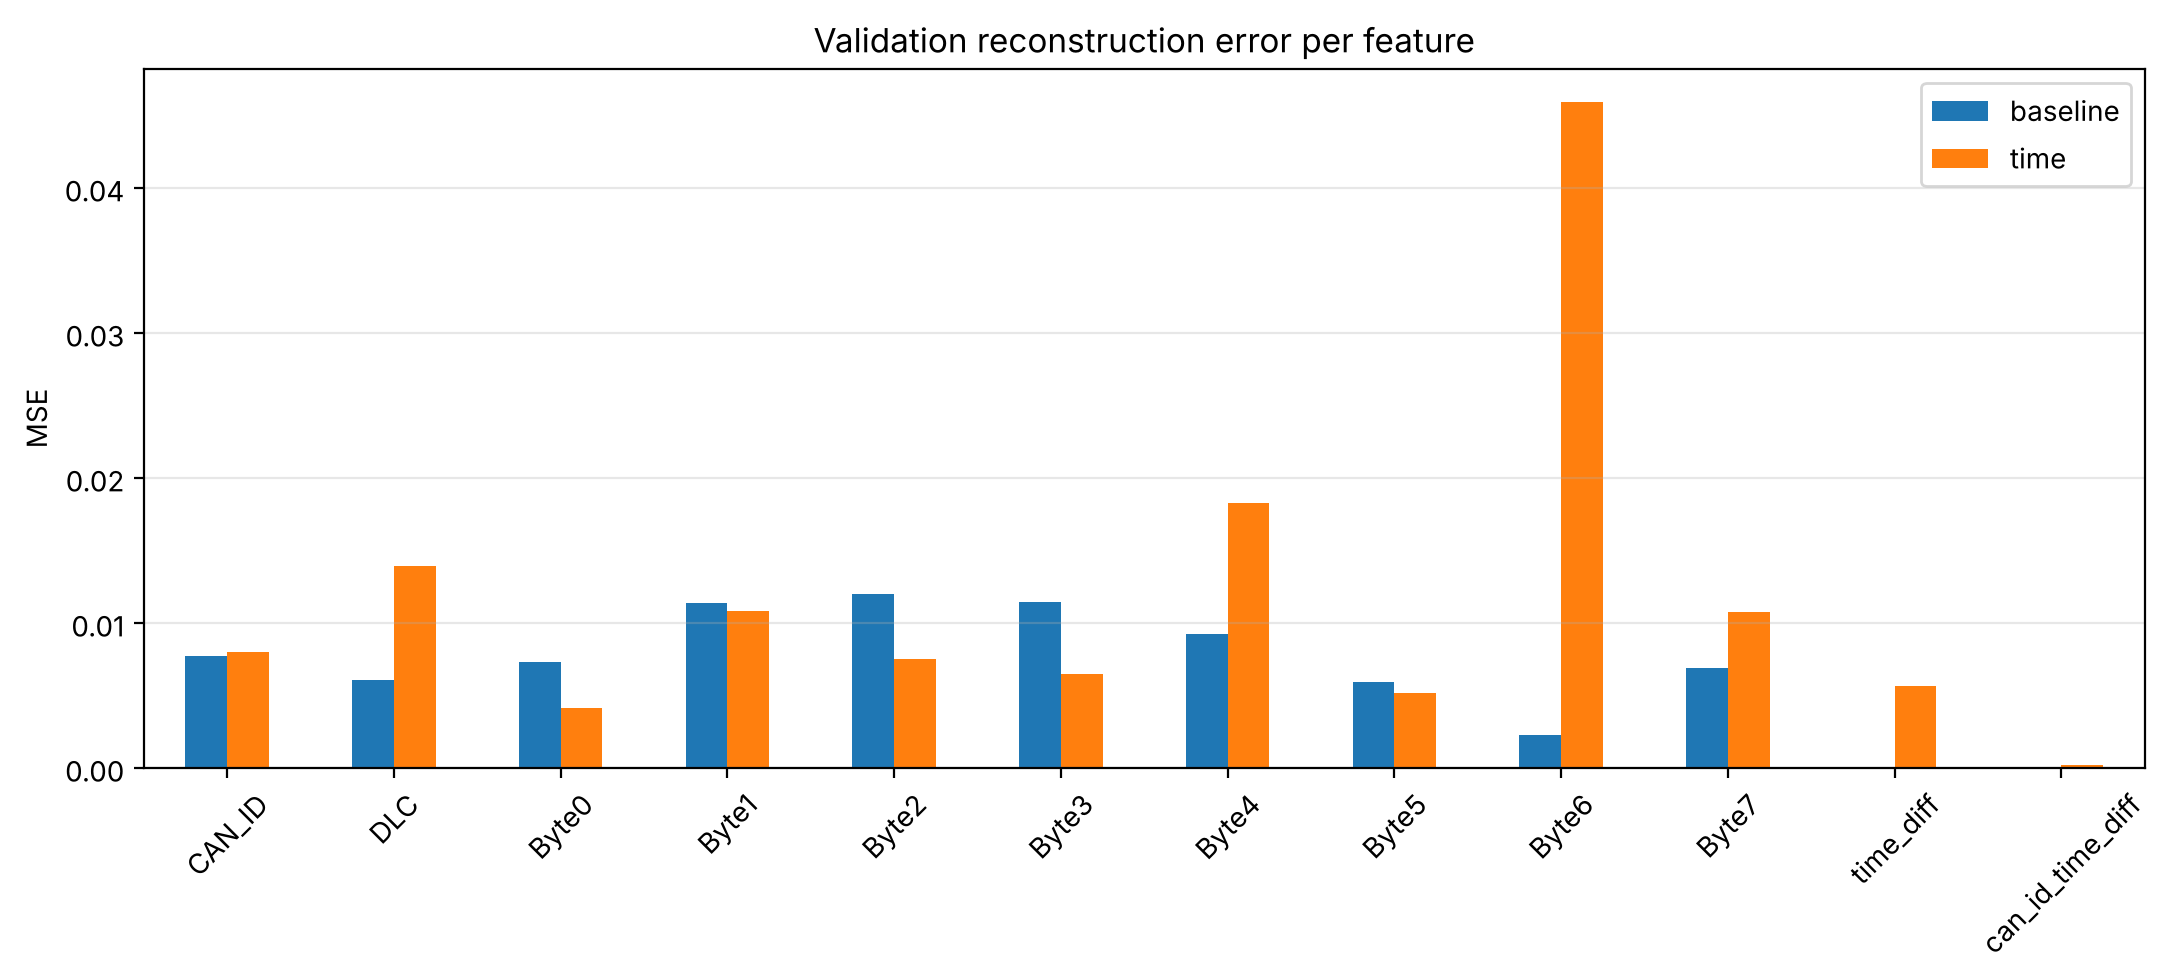

In [ ]:
per_feature.plot(kind="bar", figsize=(11, 5))
plt.title("Validation reconstruction error per feature")
plt.ylabel("MSE")
plt.xticks(rotation=45)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("error_per_feature.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Save Result

In [ ]:
for name in models:
    models[name].save(f"{name}_autoencoder.keras")
    pd.DataFrame(histories[name]).to_csv(f"{name}_history.csv", index_label="epoch")
    pd.DataFrame({"error": train_errors[name]}).to_csv(f"{name}_train_errors.csv", index=False)
    pd.DataFrame({"error": val_errors[name]}).to_csv(f"{name}_validation_errors.csv", index=False)

per_feature.to_csv("error_per_feature.csv", index_label="feature")
print("Saved")

Saved


## 7. Notes
- Baseline (10 features): training and validation loss went down together and stayed close, so the model is not overfitting. Validation error (0.0080) is almost the same as train error (0.0081).
- Time model (12 features): also no overfitting, train loss 0.0111 and validation loss 0.0114, and the train and validation error distributions overlap.
- On the 10 features both models share, the time model has a higher error (0.0131 vs 0.0080). Most of it comes from Byte6 (0.046 vs 0.002), Byte4 and DLC. The bottleneck is still 4 neurons but now it has to hold 12 features, so the model gives up some of the byte information.
- The time model loss was still going down at epoch 20, so it did not fully converge yet. More epochs or a bigger bottleneck can be tried in the tuning step.
- can_id_time_diff has a very small error (0.0002) because after MinMax scaling most of its values are close to 0, so the model learns it easily.
- A lower error on normal data does not mean better attack detection. Time features may help with attacks that change message timing like DoS, so the final choice between the two versions should come from the evaluation on the attack files.